In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

np.random.seed(2026)
sns.set_theme()

print("Environment Ready")
print("Numpy:",np.__version__)
print("Pandas:",pd.__version__)
print("Seaborn:",sns.__version__)

Environment Ready
Numpy: 2.4.6
Pandas: 2.2.3
Seaborn: 0.13.2


In [ ]:
n = 5000

customers = pd.DataFrame({
    "customer_id":np.arange(1, n + 1),
    "age": np.random.randint(18, 71, n),
    "annual_spend": np.random.lognormal(mean=7.5, sigma=0.55, size=n),
    "orders_per_year":np.random.poisson(lam=8, size=n) + 1,
    "satisfaction": np.random.choice([1,2,3,4,5],size=n,p=[0.04, 0.09, 0.20, 0.37, 0.30]),
    "channel": np.random.choice(["Organic", "Email", "PaidAds", "Referral"],n)
})

customers.loc[[12,130,900,2400], "annual_spend"] *= 8

display(customers.head())
print("Shape:",customers.shape)

,customer_id,age,annual_spend,orders_per_year,satisfaction,channel
0,1,19,4903.307728,9,2,Email
1,2,24,1795.175979,10,2,Referral
2,3,44,1526.993410,8,4,PaidAds
3,4,31,427.157852,10,4,Organic
4,5,31,1411.520634,7,5,Referral


Shape: (5000, 6)


Explanation: np.random.lognormal() creates positive, right-skewed monetary data. np.random.poisson() creates non-negative count-like values. np.random.choice() selects category values.

Interpretation: Each row is one customer, so the observational unit is the customer. customer_id is an identifier, not a measurement. Do not calculate its mean or standard deviation as if it represented customer behaviour.

#1A. Audit the dataset

In [ ]:
print("Rows:",len(customers))
print("Columns:",customers.shape[1])
display(customers.dtypes.to_frame("data_type"))
display(customers.isna().sum().to_frame('missing_values'))
print("Duplicate Customer IDs:",customers['customer_id'].duplicated().sum())
print("Negative Spending:",(customers['annual_spend'] < 0).sum())
print("Negative Orders:",(customers['orders_per_year'] < 0).sum())

Rows: 5000
Columns: 6


,data_type
customer_id,int64
age,int64
annual_spend,float64
orders_per_year,int64
satisfaction,int64
channel,object


,missing_values
customer_id,0
age,0
annual_spend,0
orders_per_year,0
satisfaction,0
channel,0


Duplicate Customer IDs: 0
Negative Spending: 0
Negative Orders: 0


Interpretation: An audit checks whether the data is fit for analysis. A missing value is not zero. An identifier being unique is expected, but uniqueness does not make it a useful numeric variable.

#2. Population, sample and census

In [ ]:
population = customers['annual_spend']
sample = population.sample(n = 300, random_state=42)

print("Population Size:",population.size)
print("Sample Size:",sample.size)

print("Population Mean:",round(population.mean(),2))
print("Sample Mean:",round(sample.mean(),2))

print("Population Standard Deviation:",round(population.std(ddof=0),2))
print("Sample Standard Deviation:",round(sample.std(ddof=1),2))


Population Size: 5000
Sample Size: 300
Population Mean: 2110.05
Sample Mean: 2137.18
Population Standard Deviation: 1377.3
Sample Standard Deviation: 1469.79


Explanation: sample() selects 300 observations. The random_state makes the selection reproducible. Population parameters describe the whole population; sample statistics estimate those parameters.

Interpretation: The sample mean will usually not equal the population mean. This difference is sampling variability, not necessarily a coding error. A different random sample can produce a different estimate.

#Compare repeated random samples

Average of 100 sample means: 2106.22
Population mean: 2110.05
Standard deviation of sample means: 70.3


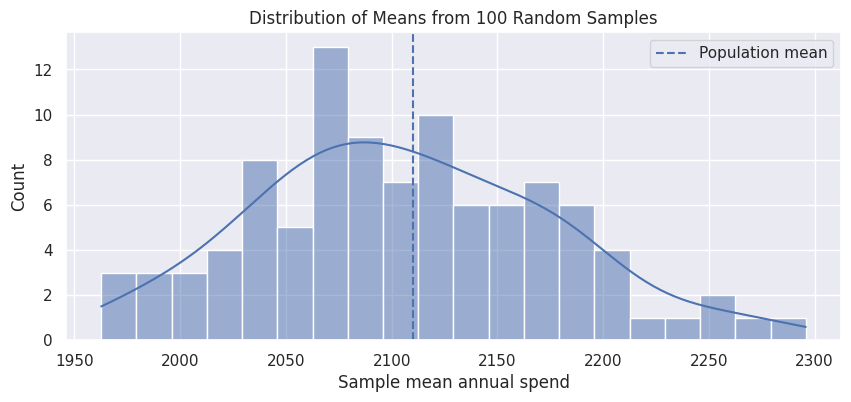

In [ ]:
sample_means = []


for seed in range(100):
  one_sample = population.sample(n=300, random_state=seed)
  sample_means.append(one_sample.mean())

sample_means = pd.Series(sample_means)

print("Average of 100 sample means:", round(sample_means.mean(), 2))
print("Population mean:", round(population.mean(), 2))
print("Standard deviation of sample means:", round(sample_means.std(), 2))

plt.figure(figsize=(10, 4))
sns.histplot(sample_means, bins=20, kde=True)
plt.axvline(population.mean(), linestyle="--", label="Population mean")
plt.title("Distribution of Means from 100 Random Samples")
plt.xlabel("Sample mean annual spend")
plt.legend()
plt.show()

Interpretation: The histogram is a sampling distribution of the sample mean (approximated through repeated samples). Its spread describes how much the sample mean changes from sample to sample. Larger samples generally produce less variable sample means, all else equal.

In [ ]:
print("Channel frequencies:")
display(customers["channel"].value_counts())

print("\nSatisfaction frequencies:")
display(customers["satisfaction"].value_counts().sort_index())

print("\nSatisfaction proportions:")
display(customers["satisfaction"].value_counts(normalize=True).sort_index().round(3))

Channel frequencies:


,count
channel,
Email,1285
PaidAds,1263
Organic,1241
Referral,1211



Satisfaction frequencies:


,count
satisfaction,
1,209
2,457
3,951
4,1881
5,1502



Satisfaction proportions:


,proportion
satisfaction,
1,0.042
2,0.091
3,0.190
4,0.376
5,0.300


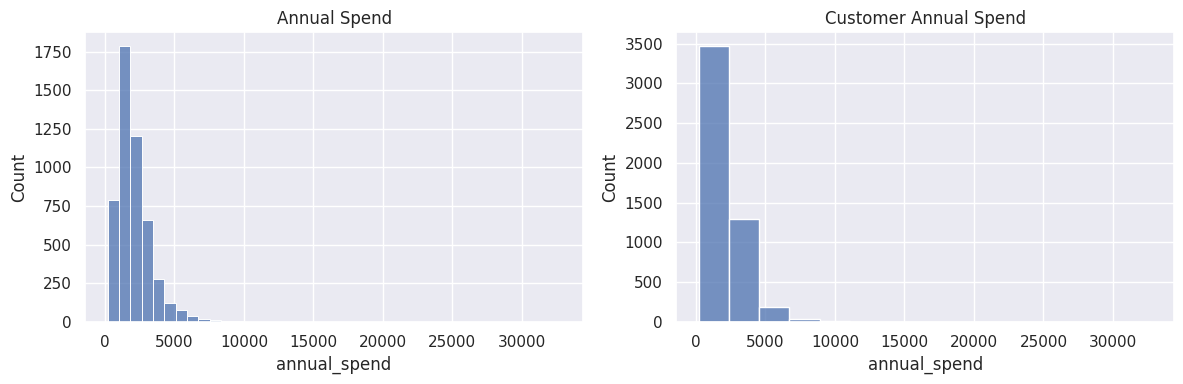

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.histplot(customers['annual_spend'], bins=40, ax=axes[0])
axes[0].set_title('Annual Spend')

sns.histplot(customers['annual_spend'], bins=15, ax=axes[1])
axes[1].set_title("Customer Annual Spend")

plt.tight_layout()
plt.show()

In [ ]:
spend = customers['annual_spend']

print("Mean:",round(spend.mean(),2))
print("Median:",round(spend.median(),2))
print("Mode(s):",round(spend.mode(),2))
print("Minimum:",round(spend.min(),2))
print("Maximum:",round(spend.max(),2))

Mean: 2110.05
Median: 1803.65
Mode(s): 0         214.90
1         222.54
2         294.88
3         304.89
4         329.83
          ...   
4995    13049.10
4996    13679.97
4997    13905.61
4998    15546.67
4999    32762.21
Name: annual_spend, Length: 5000, dtype: float64
Minimum: 214.9
Maximum: 32762.21


#Measures of dispersion

In [ ]:
def dispersion_summary(series):
  s = pd.Series(series).dropna()
  q1 = s.quantile(0.25)
  q3 = s.quantile(0.75)

  return pd.Series({
      "count":s.count(),
      "range":s.max() - s.min(),
      "sample_variance":s.var(ddof=1),
      "sample_standard_deviation":s.std(ddof=1),
      "IQR":q3 - q1,
      "coefficient_of_variation_pct":(s.std(ddof=1) / s.mean()) * 100
  })

display(dispersion_summary(spend).round(2))

,0
count,5000.00
range,32547.31
sample_variance,1897333.44
sample_standard_deviation,1377.44
IQR,1391.69
coefficient_of_variation_pct,65.28


#Same mean, different spread

In [ ]:
group_a = pd.Series([48, 49, 50, 51, 52])
group_b = pd.Series([20, 35, 50, 65, 80])

comparison = pd.DataFrame({
    "Group A":dispersion_summary(group_a),
    "Group B":dispersion_summary(group_b)
})

display(comparison.round(2))

,Group A,Group B
count,5.00,5.00
range,4.00,60.00
sample_variance,2.50,562.50
sample_standard_deviation,1.58,23.72
IQR,2.00,30.00
coefficient_of_variation_pct,3.16,47.43


#Percentiles, quartiles and IQR

In [ ]:
percentile_points = [5, 10, 25, 50, 75, 90, 95, 99]

percentile_values = spend.quantile(
    [p/100 for p in percentile_points],
    interpolation='linear'
)

percentile_table = pd.DataFrame({
    "percentile":percentile_points,
    "spend_value":percentile_values.values
})

display(percentile_table.round())

q1, median, q3 = spend.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1

print("Q1:",round(q1,2))
print("Median:",round(median,2))
print("Q3:",round(q3,2))
print("IQR:",round(iqr,2))

,percentile,spend_value
0,5,713.0
1,10,869.0
2,25,1231.0
3,50,1804.0
4,75,2622.0
5,90,3597.0
6,95,4470.0
7,99,6799.0


Q1: 1230.68
Median: 1803.65
Q3: 2622.37
IQR: 1391.69


#The empirical rule and z-scores

Within 1 standard deviation(s): 69.30%
Within 2 standard deviation(s): 94.90%
Within 3 standard deviation(s): 99.70%


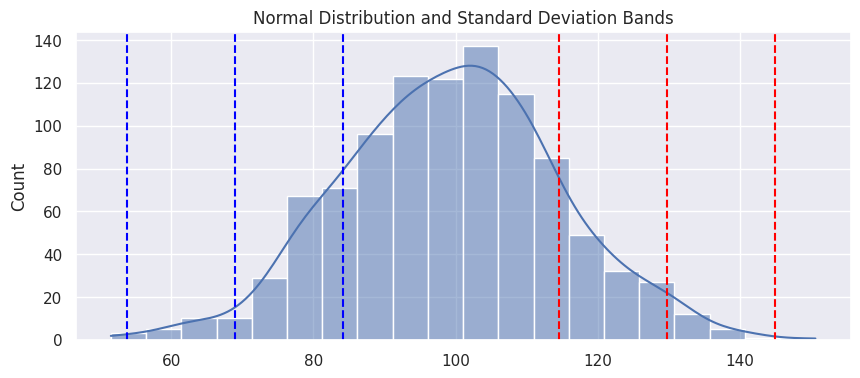

In [ ]:
normal_values = np.random.normal(loc=100, scale=15, size=1000)

mu = normal_values.mean()
sigma = normal_values.std(ddof=0)

for k in [1,2,3]:
  proportion = ((normal_values >= mu - k * sigma) &
                (normal_values <= mu + k * sigma)).mean()

  print(f"Within {k} standard deviation(s): {proportion*100:.2f}%")

plt.figure(figsize=(10,4))
sns.histplot(normal_values, bins=20, kde=True)

for k in [1,2,3]:
  plt.axvline(mu + k * sigma, linestyle="--", color='red')
  plt.axvline(mu - k * sigma, linestyle="--", color ='blue')

plt.title("Normal Distribution and Standard Deviation Bands")
plt.show()

#Calculate z-scores

In [ ]:
spend_mean = spend.mean()
spend_std = spend.std(ddof=0)

customers["spend_zscore"] = (spend - spend_mean) / spend_std

zscore_flags = customers.loc[
    customers["spend_zscore"].abs() > 3,
    ["customer_id", "annual_spend", "spend_zscore"]
].sort_values("spend_zscore", ascending=False)

print("Observations with |z-score| > 3:", len(zscore_flags))
display(zscore_flags.head(15))

Observations with |z-score| > 3: 73


,customer_id,annual_spend,spend_zscore
900,901,32762.209150,22.255258
4746,4747,15546.673295,9.755772
130,131,13905.614277,8.564268
11,12,13679.965082,8.400433
2400,2401,13049.101499,7.942389
931,932,12911.194764,7.842261
4789,4790,12763.632839,7.735122
1903,1904,12069.299687,7.230996
3666,3667,10846.477791,6.343156
810,811,10034.698871,5.753757


Interpretation: These customers are far from the mean in standard-deviation units. Because annual spend is right-skewed, z-score flags and IQR flags may identify different records. Do not assume a normal model for this spending variable.

#Covariance and correlation

In [ ]:
# Create a related variable for demonstration.
customers["customer_value_score"] = (
    0.0008 * customers["annual_spend"]
    + 0.25 * customers["orders_per_year"]
    + np.random.normal(0, 2, len(customers))
)

pair = customers[["annual_spend", "orders_per_year",
                  "age", "customer_value_score"]]

print("Covariance matrix:")
display(pair.cov().round(2))

print("Pearson correlation matrix:")
display(pair.corr(method="pearson").round(2))

Covariance matrix:


,annual_spend,orders_per_year,age,customer_value_score
annual_spend,1897333.44,20.46,-184.81,1538.66
orders_per_year,20.46,7.95,-0.28,2.07
age,-184.81,-0.28,230.18,-0.08
customer_value_score,1538.66,2.07,-0.08,5.72


Pearson correlation matrix:


,annual_spend,orders_per_year,age,customer_value_score
annual_spend,1.00,0.01,-0.01,0.47
orders_per_year,0.01,1.00,-0.01,0.31
age,-0.01,-0.01,1.00,-0.00
customer_value_score,0.47,0.31,-0.00,1.00


Interpretation: Read the correlation matrix by pairs. A positive value means the two variables tend to increase together in a linear sense. A near-zero Pearson correlation does not rule out a curved relationship.

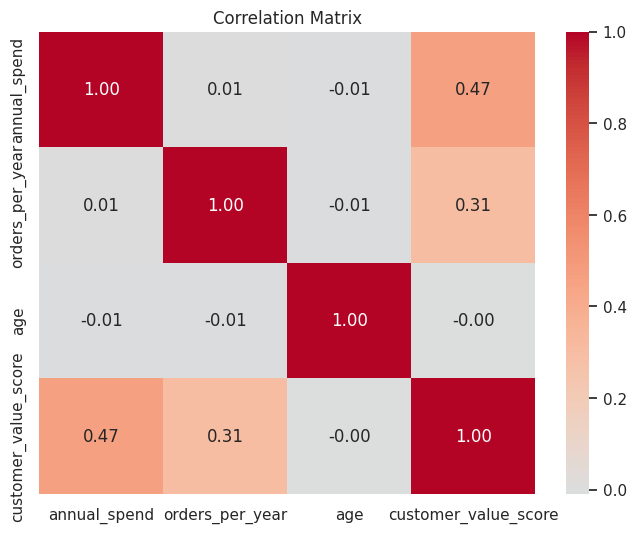

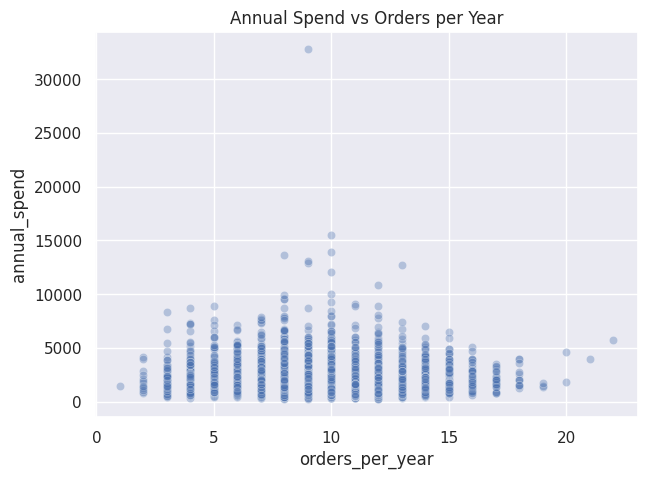

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(pair.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=customers, x="orders_per_year",
                y="annual_spend", alpha=0.35)
plt.title("Annual Spend vs Orders per Year")
plt.show()

#Confidence intervals for a population mean

A confidence interval gives a range of plausible values for a population parameter under the assumptions of the method. A 95% confidence procedure means that, over repeated random samples and intervals constructed in the same way, about 95% of those intervals would contain the true population mean.

It does not mean there is a 95% probability that this particular fixed population mean lies in the already-calculated interval (under the standard frequentist interpretation).

We use a t-interval because population standard deviation is generally unknown and estimated from the sample.

In [ ]:
sample_spend = population.sample(n=300, random_state=101)

n_sample = sample_spend.count()
sample_mean = sample_spend.mean()
sample_sd = sample_spend.std(ddof=1)
standard_error = sample_sd / np.sqrt(n_sample)

confidence = 0.95
degrees_freedom = n_sample - 1
t_critical = stats.t.ppf((1 + confidence) / 2, df=degrees_freedom)

margin_error = t_critical * standard_error
ci_lower = sample_mean - margin_error
ci_upper = sample_mean + margin_error

print("Sample size:", n_sample)
print("Sample mean:", round(sample_mean, 2))
print("Standard error:", round(standard_error, 2))
print("95% confidence interval:", (round(ci_lower, 2), round(ci_upper, 2)))

Sample size: 300
Sample mean: 1953.38
Standard error: 82.17
95% confidence interval: (np.float64(1791.68), np.float64(2115.09))


Interpretation: The interval estimates the population mean annual spend. Its width depends on variability, sample size and confidence level. A larger sample usually reduces the standard error. A higher confidence level generally widens the interval.

Assumptions and caution: The sample should be reasonably representative and observations independent. For a sufficiently large sample, the sampling distribution of the mean may be approximately normal under broad conditions, but extreme skew, dependence or biased sampling still matter.

In [ ]:
def mean_ci(series, confidence=0.95):
    s = pd.Series(series).dropna()
    n = len(s)
    mean = s.mean()
    se = s.std(ddof=1) / np.sqrt(n)
    tcrit = stats.t.ppf((1 + confidence) / 2, df=n-1)
    margin = tcrit * se
    return mean, mean - margin, mean + margin

for size in [30, 100, 300, 1000]:
    sample = population.sample(n=size, random_state=2026 + size)
    mean, low, high = mean_ci(sample)
    print(f"n={size:4d} | mean={mean:,.2f} | CI width={high-low:,.2f}")

n=  30 | mean=2,144.04 | CI width=1,292.49
n= 100 | mean=2,076.77 | CI width=547.22
n= 300 | mean=2,106.57 | CI width=325.72
n=1000 | mean=2,084.45 | CI width=153.56


Interpretation: Compare interval widths, not just the point estimates. Sample size increases generally narrow the interval, although the exact widths also depend on the sample's variability.

#Compare customer channels

In [ ]:
channel_summary = customers.groupby("channel")["annual_spend"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
)
channel_summary["q1"] = customers.groupby("channel")["annual_spend"].quantile(.25)
channel_summary["q3"] = customers.groupby("channel")["annual_spend"].quantile(.75)
channel_summary["iqr"] = channel_summary["q3"] - channel_summary["q1"]

display(channel_summary.round(2))

,count,mean,median,std,minimum,maximum,q1,q3,iqr
channel,,,,,,,,,
Email,1285,2125.92,1803.03,1420.39,329.83,15546.67,1212.39,2638.53,1426.14
Organic,1241,2095.62,1830.27,1200.88,222.54,8877.68,1231.77,2627.07,1395.30
PaidAds,1263,2110.55,1777.52,1360.77,214.90,13905.61,1244.81,2596.86,1352.05
Referral,1211,2107.49,1803.27,1512.65,294.88,32762.21,1247.60,2629.17,1381.57


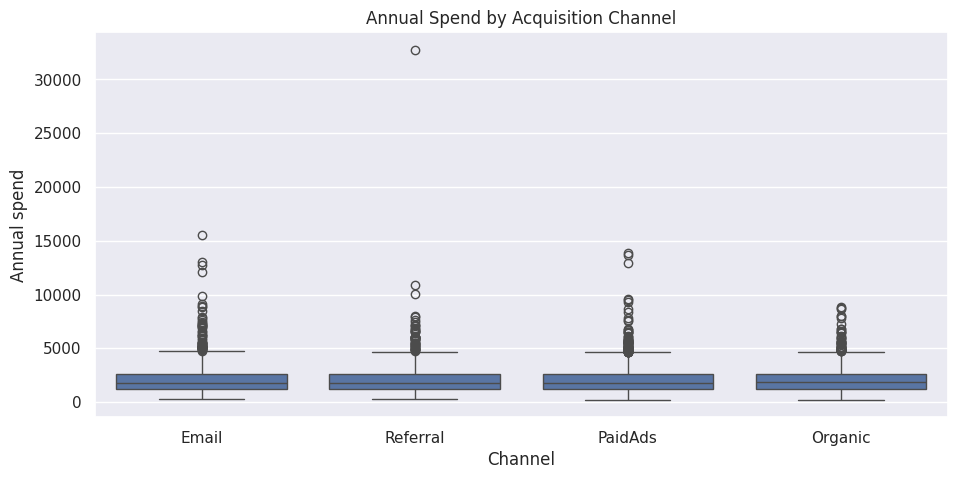

In [ ]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=customers, x="channel", y="annual_spend")
plt.title("Annual Spend by Acquisition Channel")
plt.xlabel("Channel")
plt.ylabel("Annual spend")
plt.show()

In [ ]:
def statistical_profile(series, variable_name="variable"):
    """Calculate descriptive statistics and distribution diagnostics."""
    numeric = pd.to_numeric(pd.Series(series), errors="coerce")
    valid = numeric.dropna()

    if valid.empty:
        raise ValueError(f"{variable_name} has no valid numeric observations")

    q1 = valid.quantile(0.25)
    median = valid.quantile(0.50)
    q3 = valid.quantile(0.75)
    iqr_value = q3 - q1
    lower_fence = q1 - 1.5 * iqr_value
    upper_fence = q3 + 1.5 * iqr_value
    outlier_count = ((valid < lower_fence) | (valid > upper_fence)).sum()

    return {
        "variable": variable_name,
        "count": int(valid.count()),
        "missing": int(numeric.isna().sum()),
        "mean": valid.mean(),
        "median": median,
        "mode": valid.mode().iloc[0],
        "sample_std": valid.std(ddof=1),
        "sample_variance": valid.var(ddof=1),
        "min": valid.min(),
        "q1": q1,
        "q3": q3,
        "max": valid.max(),
        "range": valid.max() - valid.min(),
        "iqr": iqr_value,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "outlier_count": int(outlier_count),
        "outlier_pct": outlier_count / len(valid) * 100,
        "skewness": valid.skew()
    }

profile = pd.DataFrame([
    statistical_profile(customers[col], col)
    for col in ["age", "annual_spend", "orders_per_year",
                "satisfaction"]
])

display(profile.round(2))

,variable,count,missing,mean,median,mode,sample_std,sample_variance,min,q1,q3,max,range,iqr,lower_fence,upper_fence,outlier_count,outlier_pct,skewness
0,age,5000,0,43.84,44.00,45.0,15.17,230.18,18.0,31.00,57.00,70.00,52.00,26.00,-8.00,96.00,0,0.00,0.01
1,annual_spend,5000,0,2110.05,1803.65,214.9,1377.44,1897333.44,214.9,1230.68,2622.37,32762.21,32547.31,1391.69,-856.86,4709.91,214,4.28,4.29
2,orders_per_year,5000,0,8.99,9.00,8.0,2.82,7.95,1.0,7.00,11.00,22.00,21.00,4.00,1.00,17.00,19,0.38,0.39
3,satisfaction,5000,0,3.80,4.00,4.0,1.09,1.19,1.0,3.00,5.00,5.00,4.00,2.00,0.00,8.00,0,0.00,-0.79
